# **1 - Install Dependencies**

In [1]:

!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

# **2 - Load a compact LLM**

In [2]:

import os
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

print("PhishGuard AI initialized.")


PhishGuard AI initialized.


# **3 - Create a starter security knowledge base**

In [3]:

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

with open("sms_dataset.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("sms_dataset.zip", "r") as archive:
    archive.extractall("sms_data")

data_path = "sms_data/SMSSpamCollection"

df = pd.read_csv(
    data_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset shape:", df.shape)
print(df.head())
print("\nClass distribution:")
print(df["label"].value_counts())


Dataset shape: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


# **4 - Build the retrieval index**

In [4]:

df = df.dropna(subset=["message", "label"]).copy()

df["message"] = df["message"].astype(str).str.strip()
df["label"] = df["label"].str.strip().str.lower()

df = df[
    df["label"].isin(["ham", "spam"]) &
    (df["message"] != "")
].copy()

df["target"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print("Clean dataset:", df.shape)
print(df["target"].value_counts())


Clean dataset: (5572, 3)
target
0    4825
1     747
Name: count, dtype: int64


# **5 - Generate evidence-based answers**

In [5]:

X = df["message"]
y = df["target"]

# 70% training, 15% validation, 15% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))


Training: 3900
Validation: 836
Testing: 836


# **6 - Test retrieval and prompt-injection handling**

In [6]:

text_features = FeatureUnion([
    (
        "word",
        TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            max_features=30000,
            sublinear_tf=True
        )
    ),
    (
        "character",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            max_features=30000,
            sublinear_tf=True
        )
    )
])

model = Pipeline([
    ("features", text_features),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

model.fit(X_train, y_train)

print("Training completed successfully.")


Training completed successfully.


# **7 - Evaluate the model**

VALIDATION RESULTS
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       724
        Spam       0.99      0.94      0.96       112

    accuracy                           0.99       836
   macro avg       0.99      0.97      0.98       836
weighted avg       0.99      0.99      0.99       836


TEST RESULTS
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       724
        Spam       0.97      0.93      0.95       112

    accuracy                           0.99       836
   macro avg       0.98      0.96      0.97       836
weighted avg       0.99      0.99      0.99       836

ROC-AUC: 0.9932665745856353
PR-AUC: 0.9848057965827485


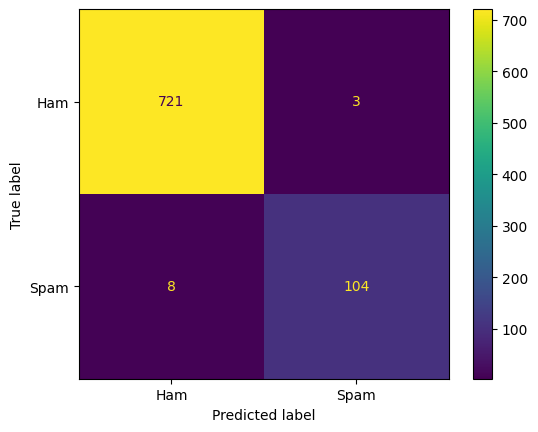

In [7]:

# Validation predictions
val_scores = model.predict_proba(X_val)[:, 1]

# Initial threshold: 0.5
val_predictions = (val_scores >= 0.5).astype(int)

print("VALIDATION RESULTS")
print(classification_report(
    y_val,
    val_predictions,
    target_names=["Ham", "Spam"]
))

# Final test evaluation at the same threshold
test_scores = model.predict_proba(X_test)[:, 1]
test_predictions = (test_scores >= 0.5).astype(int)

print("\nTEST RESULTS")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Ham", "Spam"]
))

print("ROC-AUC:", roc_auc_score(y_test, test_scores))
print("PR-AUC:", average_precision_score(y_test, test_scores))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Ham", "Spam"]
)
plt.show()


# **8 - Tune the detection threshold**

In [8]:

precision, recall, thresholds = precision_recall_curve(
    y_val, val_scores
)

MIN_PRECISION = 0.80

valid_indices = np.where(
    precision[:-1] >= MIN_PRECISION
)[0]

if len(valid_indices):
    best_index = valid_indices[
        np.argmax(recall[:-1][valid_indices])
    ]
    BEST_THRESHOLD = float(thresholds[best_index])
else:
    BEST_THRESHOLD = 0.5
    print("Precision target not achieved; using baseline threshold.")

print("Selected threshold:", BEST_THRESHOLD)

# Evaluate selected threshold on the untouched test set
final_predictions = (
    test_scores >= BEST_THRESHOLD
).astype(int)

print(classification_report(
    y_test,
    final_predictions,
    target_names=["Ham", "Spam"]
))


Selected threshold: 0.21992670338147555
              precision    recall  f1-score   support

         Ham       1.00      0.96      0.98       724
        Spam       0.77      0.97      0.86       112

    accuracy                           0.96       836
   macro avg       0.88      0.96      0.92       836
weighted avg       0.97      0.96      0.96       836



# **9 - Test your own messages**

In [9]:

def detect_message(message):
    score = float(model.predict_proba([message])[0, 1])

    if score >= BEST_THRESHOLD:
        classification = "SPAM / SUSPICIOUS"
    else:
        classification = "LIKELY LEGITIMATE"

    return {
        "classification": classification,
        "risk_score": round(score * 100, 2),
        "threshold": round(BEST_THRESHOLD, 3)
    }


test_messages = [
    "Congratulations! You won a free prize. Call now!",
    "Hey, are we still meeting for coffee tomorrow?",
    "URGENT: Your account is suspended. Verify immediately."
]

for message in test_messages:
    print("\nMessage:", message)
    print(detect_message(message))



Message: Congratulations! You won a free prize. Call now!
{'classification': 'SPAM / SUSPICIOUS', 'risk_score': 92.4, 'threshold': 0.22}

Message: Hey, are we still meeting for coffee tomorrow?
{'classification': 'LIKELY LEGITIMATE', 'risk_score': 6.63, 'threshold': 0.22}

Message: URGENT: Your account is suspended. Verify immediately.
{'classification': 'SPAM / SUSPICIOUS', 'risk_score': 45.81, 'threshold': 0.22}


# **10 - Save your model**

In [10]:

joblib.dump(
    {
        "model": model,
        "threshold": BEST_THRESHOLD,
        "version": "0.1",
        "dataset": "UCI SMS Spam Collection"
    },
    "phishguard_sms_v0_1.joblib"
)

print("Model exported successfully.")


Model exported successfully.
